# D3M demo: does the monitor alarm only when the model actually gets worse?

Paper: Nguyen, Shui, Giri, Arya, Verma, Razak, Krishnan. *Reliably Detecting Model Failures in Deployment Without Labels.* NeurIPS 2025 (arXiv 2506.05047).

**The problem in one chain**
1. A model is trained once and then deployed. The incoming data slowly changes. This is called **distribution shift**.
2. Some shifts make the model worse. The paper calls this **post-deployment deterioration (PDD)**. Other shifts are harmless.
3. In deployment we have no labels, so we cannot measure accuracy directly.
4. Classic drift detectors (KS test, BBSD) alarm on *any* change, harmless or not. That causes **alert fatigue**: too many alarms nobody acts on.
5. D3M tries to alarm *only* on harmful shifts. It does this by measuring how much "plausible alternative models" disagree with the deployed model on the new data.

**Summary.** D3M is a label-free monitor that should stay quiet on harmless shifts and alarm on harmful ones.
**Key terms:** distribution shift, post-deployment deterioration, label-free monitoring, alert fatigue.

Run the cells from top to bottom. The first cell takes a few seconds; every interaction after that takes about a second.

In [1]:
import sys, os, time, json
sys.path.insert(0, os.path.abspath("."))
import numpy as np, torch, matplotlib.pyplot as plt
from src import data, experiments as E, plots, baselines
torch.set_num_threads(max(1, os.cpu_count() // 2))

t0 = time.perf_counter()
st = E.load_or_build_setup(0, "results/checkpoints/model_seed0.pt")   # trained base model (seed 0)
monitors = {}                                                          # (K, tau) -> calibrated D3M
def get_monitor(K=5000, tau=1.0):
    if (K, tau) not in monitors:
        monitors[(K, tau)] = E.make_monitor(st, K=K, temperature=tau)
    return monitors[(K, tau)]
mon = get_monitor()
for m in E.M_GRID:                       # Calibrate stage: one Phi per batch size m
    mon.calibrate(st.X_val, m)
print(f"ID accuracy of the deployed model: {st.id_acc:.3f}")
print(f"start-up (load model + calibrate {len(E.M_GRID)} batch sizes, T = {mon.T}, K = {mon.K}): "
      f"{time.perf_counter() - t0:.1f} s")

ID accuracy of the deployed model: 0.848
start-up (load model + calibrate 6 batch sizes, T = 1000, K = 5000): 2.6 s


## 1. How D3M works (Train, Calibrate, Deploy)

1. **Train.** A feature network plus a **Variational Bayesian Last Layer (VBLL)**. VBLL learns a Gaussian *distribution* over the weights of the final layer instead of a single weight matrix. For every input x it therefore gives a Gaussian over the class scores (**logits**). The deployed model *f* uses the mean of that Gaussian.
2. **One batch → one number φ.** Take m unlabelled inputs.
   - (a) The deployed model's labels ȳᵢ are called **pseudo-labels**.
   - (b) Draw K random logit vectors from the Gaussian, divide them by a **temperature** τ, apply softmax, and *sample* a label ŷᵢ⁽ᵏ⁾ from the result.
   - (c) For each draw k, the **disagreement rate** is the fraction of the m points where ŷ ≠ ȳ.
   - (d) **φ = the largest disagreement rate over the K draws.**
3. **Calibrate.** Repeat step 2 on T = 1000 random batches (drawn with replacement, a **bootstrap**) from held-out in-distribution (ID) data. This gives a reference histogram Φ: "how big φ usually is when nothing has changed".
4. **Deploy.** Compute φ̃ for the new batch. Alarm if φ̃ ≥ the (1−α) **quantile** of Φ, where α is the **significance level** (the false-alarm rate we accept).

What the code revealed (see FEASIBILITY_REPORT.md):
- The K draws are independent *for every point*. So φ is really "how many borderline-looking points are in the batch, plus a max-over-K bonus".
- D3M alarms only if disagreement goes **up**.

**Summary.** φ measures how unsure the model's own posterior is about this batch; the alarm fires when φ̃ is unusually high compared with ID batches.
**Key terms:** VBLL posterior, pseudo-label, maximum disagreement rate φ, quantile threshold.

## 2. Where does D3M "see" disagreement?

The background shows p(x), the chance that one D3M draw disagrees with the model at input x.
- **Dark** means the model is unsure; D3M counts many disagreements there.
- The black line is the **true** boundary; the dashed line is the **model's** boundary.
- The labels show where each shift (at full strength) moves the data.

Look at the right-hand side. The model's dashed boundary stays flat while the true boundary bends upward, yet the background is *not* darker there. The posterior is confident even where the model is wrong.

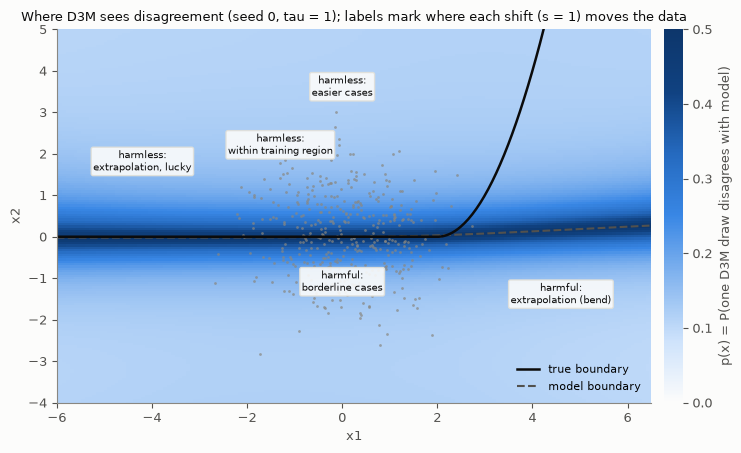

In [2]:
fig = plots.fig_e1(st); plt.show()

## 3. Panel A: harmless vs harmful shift (live)

**Predict, then run.** Before you move a control, say what you expect for: the true accuracy, D3M's φ̃ relative to the dashed threshold, and the KS and BBSD alarms.

Controls:
- **shift**, the kind of drift. Two are harmful and three are harmless. Harmfulness is *measured*: the title says HARMFUL if the true accuracy drops more than 5 points.
- **strength s**: 0 means no shift, 1 means full shift.
- **m**: query batch size. **alpha**: significance level.
- **K, tau**: D3M's number of posterior draws and its temperature. A new (K, τ) pair recalibrates Φ for this m, which takes about 1 s.
- **batch seed**: draws a different random query batch.

Left plot: data, boundaries and the query batch (orange; × = the model is wrong). Right plot: histogram of Φ, the threshold (dashed) and the query's φ̃ (orange line).

In [3]:
import ipywidgets as w

def show_panel_a(kind="harmful_boundary", s=0.5, m=100, alpha=0.1, K=5000, tau=1.0, batch_seed=1):
    t0 = time.perf_counter()
    fig = plots.panel_a(st, get_monitor(K, tau), kind, s, m, alpha, seed=batch_seed)
    plt.show()
    i = fig.info
    print(f"phi~ = {i['phi']:.3f}, threshold = {i['threshold']:.3f}  ->  D3M {'ALARM' if i['d3m'] else 'quiet'}"
          f"   (tie-broken p-value {i['p_value_tiefix']:.3f})")
    print(f"true accuracy (population) = {i['acc']:.3f}, on this batch = {i['batch_acc']:.3f}, ID = {i['id_acc']:.3f}")
    print(f"recomputed and redrawn in {time.perf_counter() - t0:.2f} s")

controls = dict(
    kind=w.Dropdown(options=[(plots.KIND_LABEL[k], k) for k in data.SHIFT_KINDS], value="harmful_boundary", description="shift"),
    s=w.FloatSlider(value=0.5, min=0, max=1, step=0.05, description="strength s"),
    m=w.SelectionSlider(options=list(E.M_GRID), value=100, description="batch m"),
    alpha=w.FloatSlider(value=0.1, min=0.01, max=0.3, step=0.01, description="alpha"),
    K=w.Dropdown(options=[1, 10, 100, 1000, 5000, 50000], value=5000, description="K"),
    tau=w.Dropdown(options=[0.25, 0.5, 1.0, 2.0, 5.0, 10.0], value=1.0, description="tau"),
    batch_seed=w.IntSlider(value=1, min=0, max=50, description="batch seed"),
)
ui = w.VBox([w.HBox([controls["kind"], controls["s"], controls["m"]]),
             w.HBox([controls["alpha"], controls["K"], controls["tau"], controls["batch_seed"]])])
display(ui, w.interactive_output(show_panel_a, controls))

Output()

**Fallback (if the widgets do not render):** edit the variables and re-run this cell.

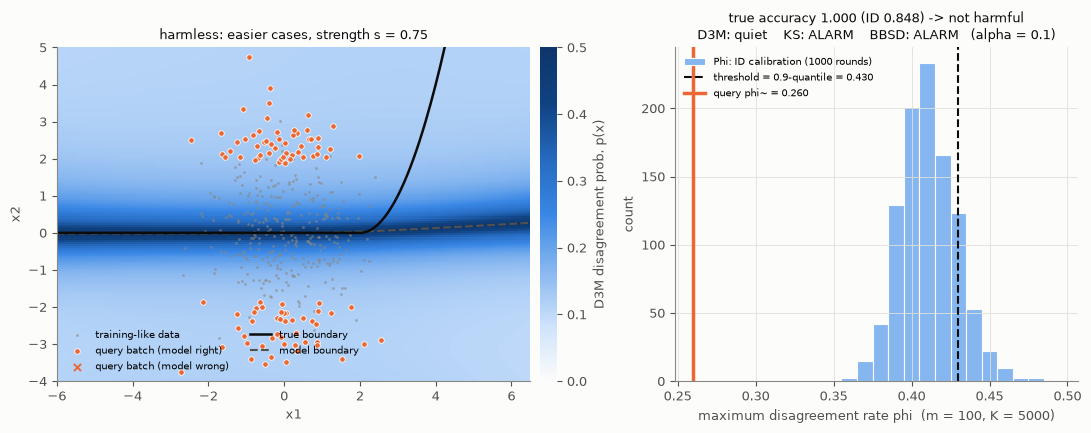

phi~ = 0.260, threshold = 0.430  ->  D3M quiet   (tie-broken p-value 1.000)
true accuracy (population) = 1.000, on this batch = 1.000, ID = 0.848
recomputed and redrawn in 0.76 s


In [4]:
kind = "harmless_easier"    # none | harmful_boundary | harmful_extrapolation | harmless_easier | harmless_support | harmless_luck
s, m, alpha, K, tau, batch_seed = 0.75, 100, 0.1, 5000, 1.0, 1
show_panel_a(kind, s, m, alpha, K, tau, batch_seed)

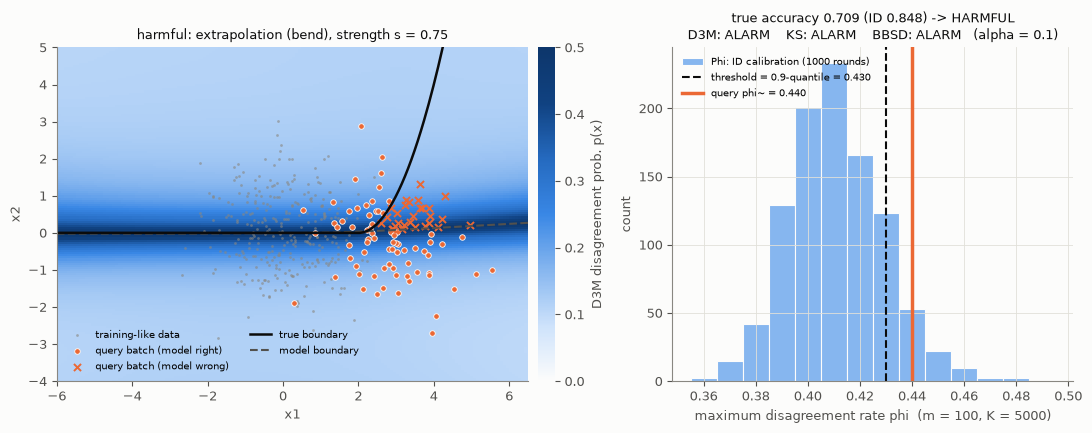

phi~ = 0.440, threshold = 0.430  ->  D3M ALARM   (tie-broken p-value 0.059)
true accuracy (population) = 0.709, on this batch = 0.660, ID = 0.848
recomputed and redrawn in 0.68 s


In [5]:
# The weak spot: the model is confidently wrong in the bend (accuracy ~0.71).
# Over 5 seeds x 200 batches D3M alarms on only ~32% of such batches (E3), KS on 100%.
# Change the last argument (batch seed) a few times to see how often D3M stays quiet.
show_panel_a("harmful_extrapolation", 0.75, 100, 0.1, 5000, 1.0, 1)

## 4. Panel B: how much data does the monitor need?

1. For one shift, draw R random query batches for each batch size m.
2. Count how often each detector alarms. Under a harmful shift this is the **true positive rate (TPR)**. Under no shift or a harmless shift it is the **false positive rate (FPR)**.
3. A good monitor has a high TPR at small m and an FPR near α.

The live version below uses R = 100 batches per m and takes roughly 15–40 s. The 5-seed version (R = 200) is in `results/figures/e4_batch_size.png`.

**Key terms:** true positive rate, false positive rate, sample complexity.

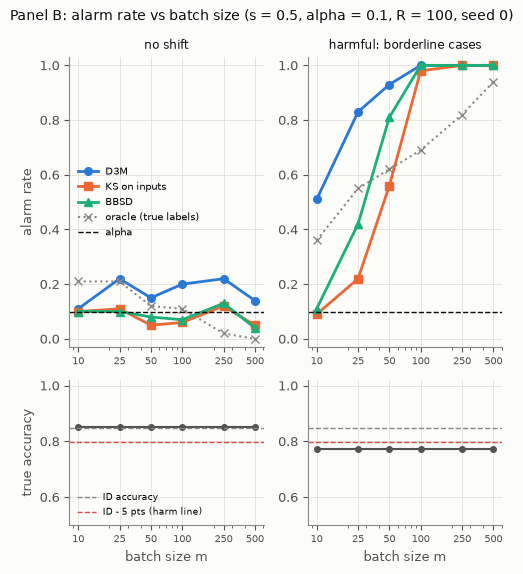

computed in 9.8 s


In [6]:
def show_panel_b(kind="harmful_boundary", s=0.5, alpha=0.1, R=100):
    t0 = time.perf_counter()
    res = E.batch_size_sweep(st, mon, ["none", kind], s, alpha, R)
    fig = plots.fig_rates([res], ["none", kind], E.M_GRID, lambda k, m: f"{k}|{m}", "batch size m",
                          f"Panel B: alarm rate vs batch size (s = {s}, alpha = {alpha}, R = {R}, seed 0)",
                          alpha=alpha, logx=True)
    plt.show()
    print(f"computed in {time.perf_counter() - t0:.1f} s")

show_panel_b("harmful_boundary", 0.5)

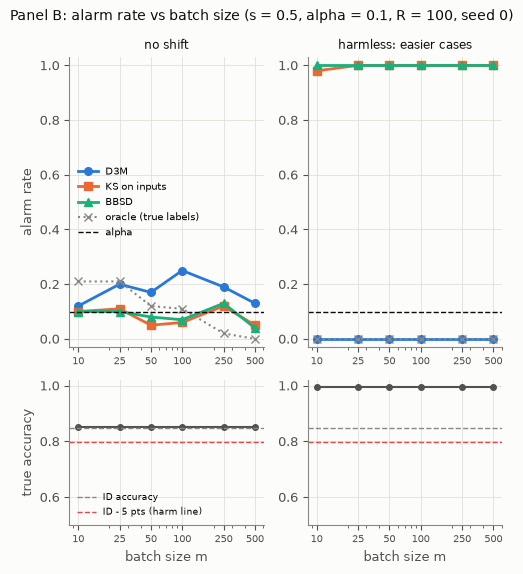

computed in 10.7 s


In [7]:
show_panel_b("harmless_easier", 0.5)

## 5. Panel C: a monitoring timeline

One batch of m = 100 per day.
- Days 0–19: no shift.
- Days 20–39: a harmless drift.
- Days 40–59: a harmful drift that grows each day.

The red band marks days where the true accuracy is more than 5 points below ID. Count the false alarms before the band, and how many days each detector takes to fire inside it.

In [8]:
def show_panel_c(name):
    t0 = time.perf_counter()
    res = E.e7_timeline(st, mon, name)
    fig = plots.fig_e7({name: res}, st.id_acc); plt.show()
    for det, v in res["summary"].items():
        print(f"{det:7s} false alarms {v['false_alarms']:2d}/{v['n_ok_days']} ok days,  "
              f"delay after onset: {v['delay']} days,  alarm rate after onset {v['hit_rate_after_onset']:.2f}")
    print(f"computed in {time.perf_counter() - t0:.1f} s")

w.interact(show_panel_c, name=w.Dropdown(options=list(E.TIMELINES)));

interactive(children=(Dropdown(description='name', options=('A: easier cases, then borderline cases', 'B: with…

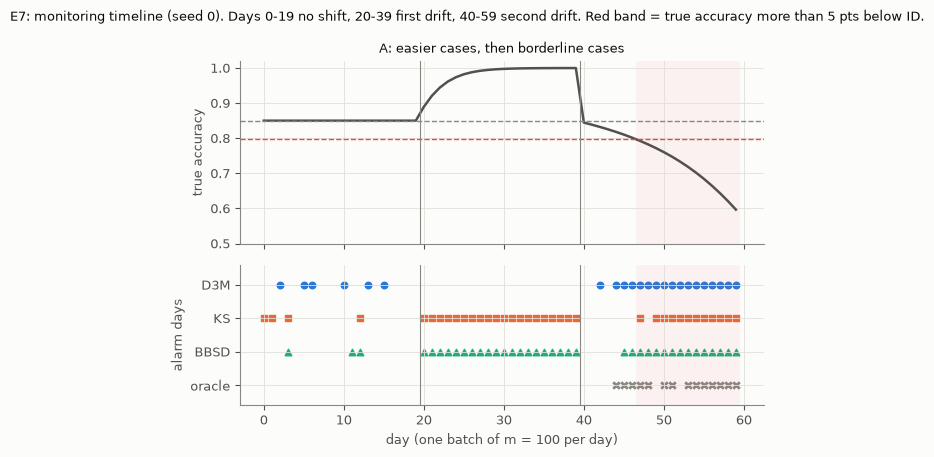

d3m     false alarms 10/47 ok days,  delay after onset: 0 days,  alarm rate after onset 1.00
ks      false alarms 24/47 ok days,  delay after onset: 0 days,  alarm rate after onset 0.92
bbsd    false alarms 25/47 ok days,  delay after onset: 0 days,  alarm rate after onset 1.00
oracle  false alarms  3/47 ok days,  delay after onset: 0 days,  alarm rate after onset 0.85
computed in 2.2 s


In [9]:
show_panel_c("A: easier cases, then borderline cases")    # fallback without widgets

## 6. Results from the full feasibility run (5 seeds)

These are the stored numbers from `run_spike.py`; the notebook does not recompute them.

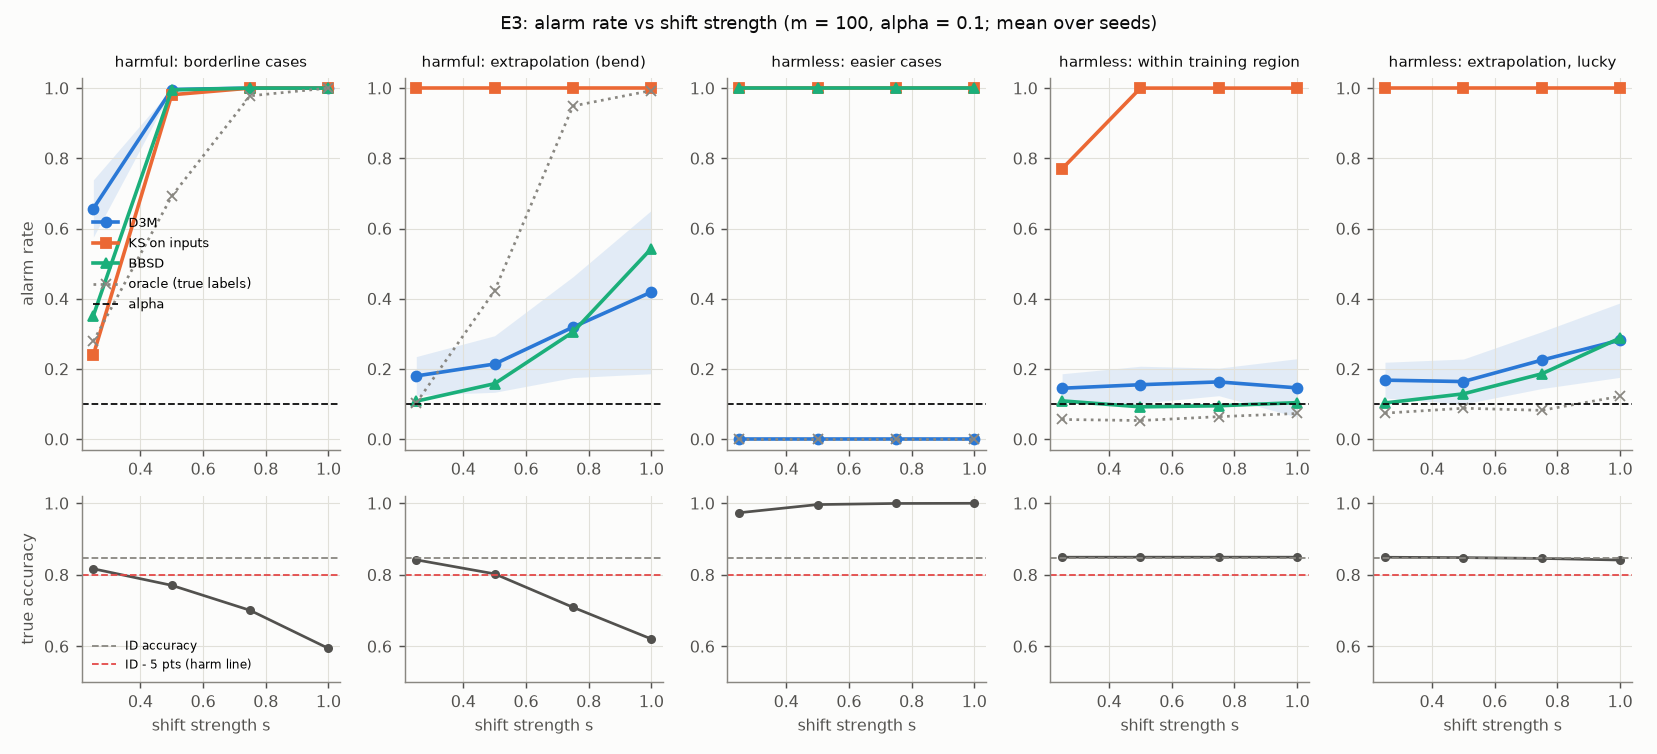

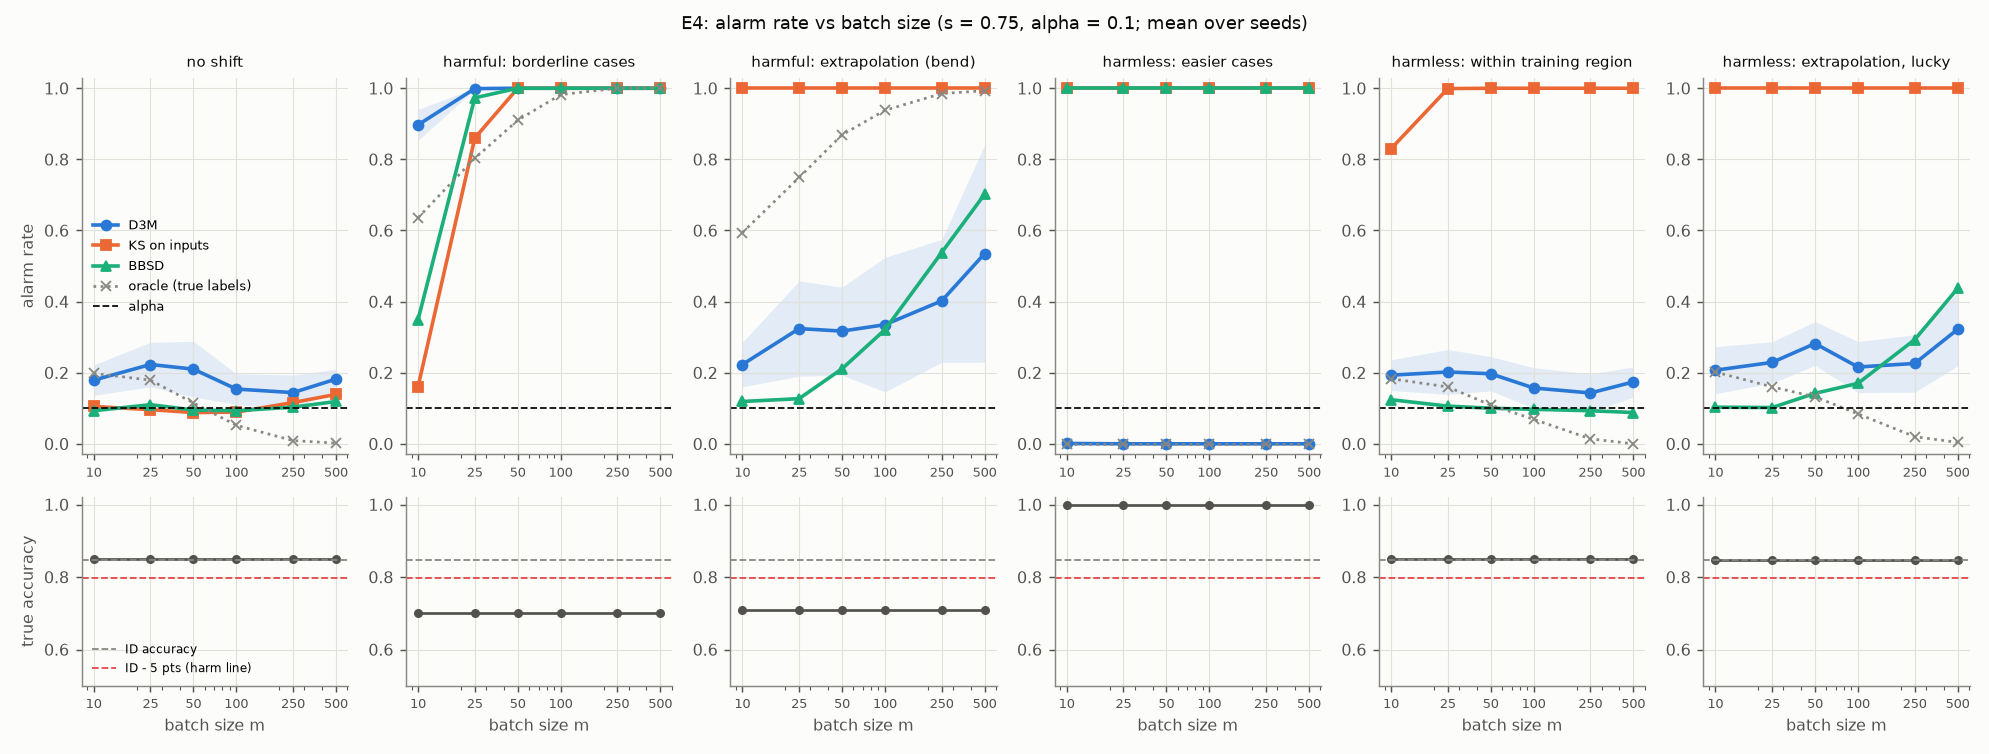

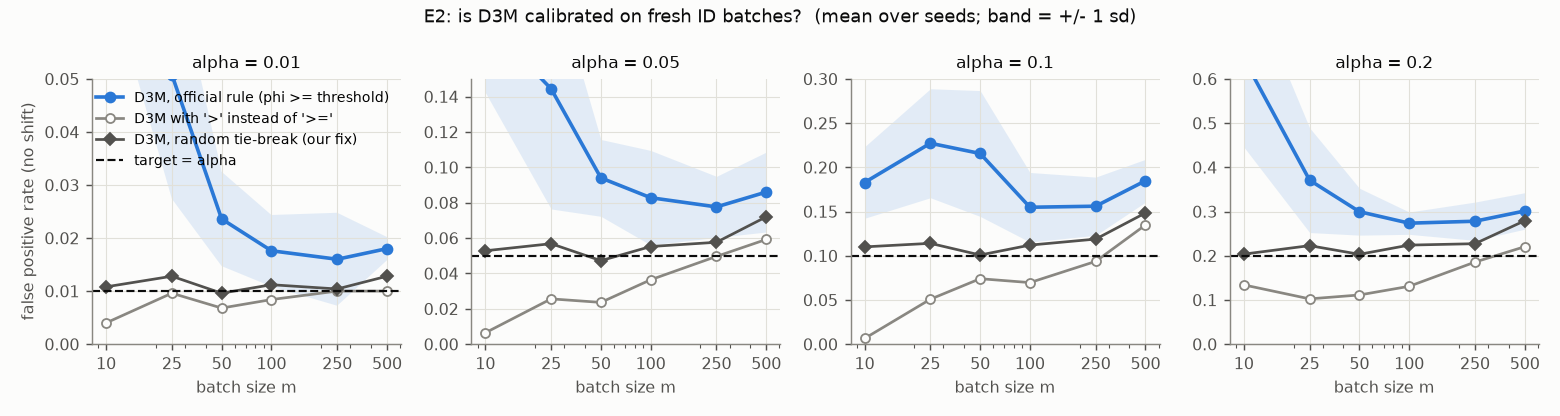

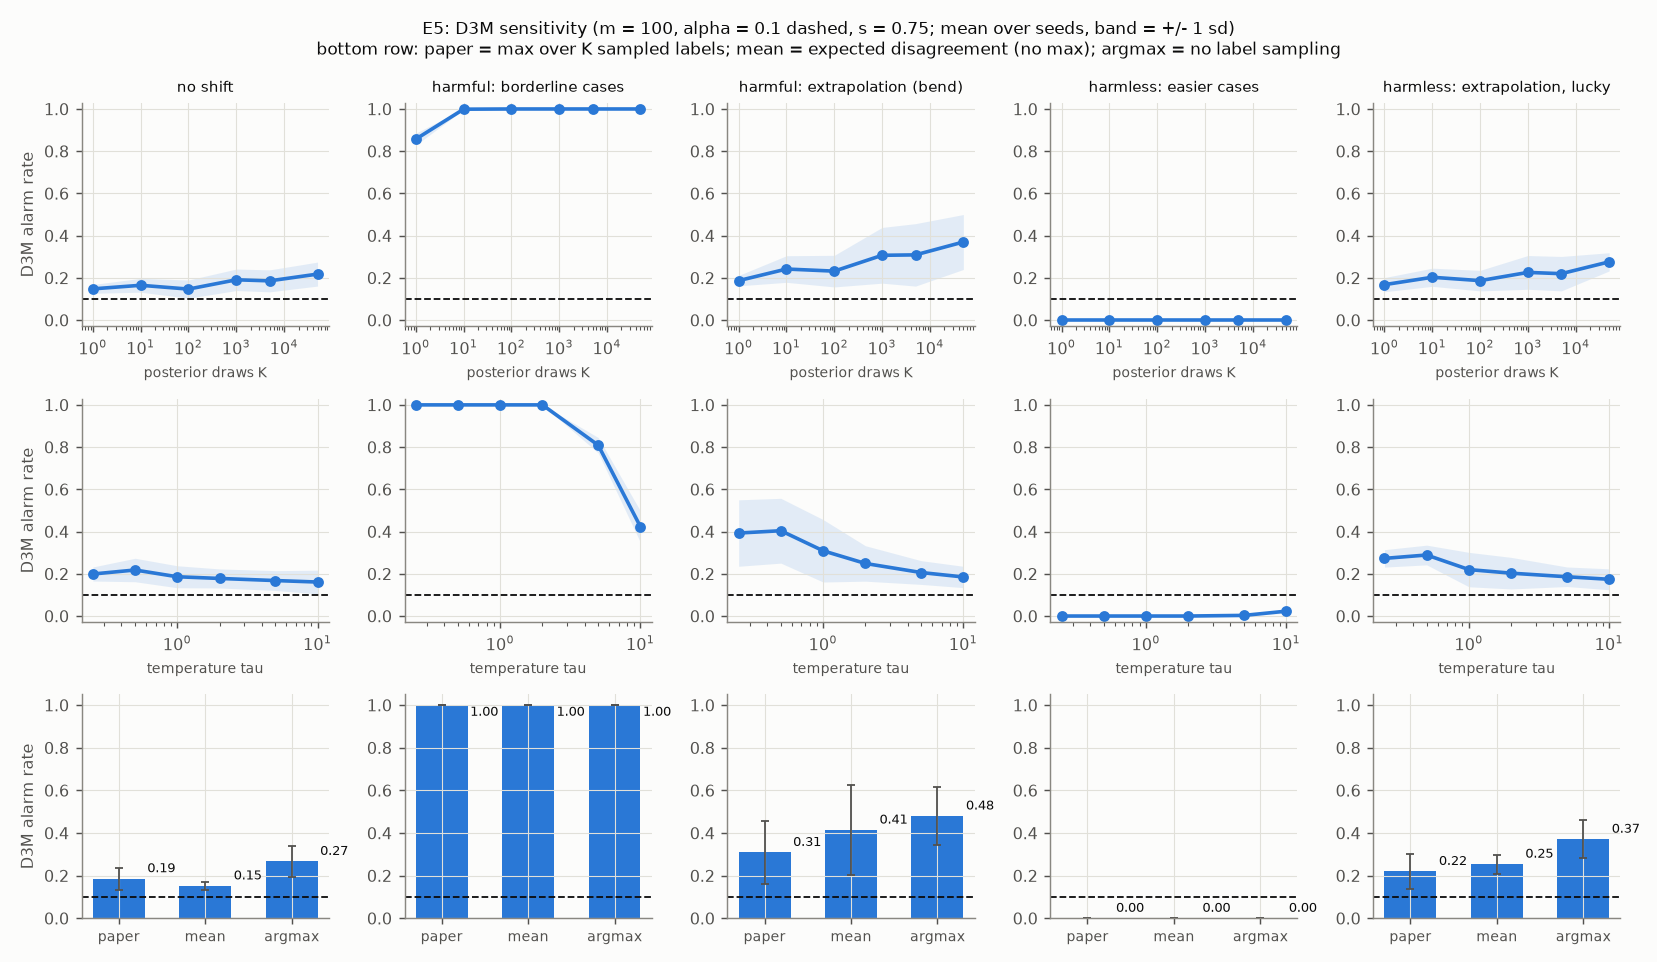

In [10]:
from IPython.display import Image, display
for f in ["e3_shift_strength.png", "e4_batch_size.png", "e2_fpr_no_shift.png", "e5_sensitivity.png"]:
    display(Image(filename=f"results/figures/{f}"))

## Summary

Numbers below are from the 5-seed run (m = 100, α = 0.1).

1. D3M's alarm depends on whether the batch contains *more points the model is unsure about* than ID batches do.
2. So it stays quiet when data becomes easier: an alarm rate of 0.00, while KS and BBSD both alarm at 1.00. This is the paper's main selling point, and it reproduces here.
3. It alarms reliably when a shift adds borderline cases (1.00 from m = 25 on). At m = 10 it is the best detector.
4. It mostly **misses** a shift into a region where the model is *confidently wrong* (the bend): 0.42 at full strength, where the accuracy drops from 0.85 to 0.62. It also alarms almost as often (0.28) on the harmless mirror-image shift, so out there it barely separates harmful from harmless.
5. The official `≥` rule gives a false positive rate of 0.15–0.23 instead of 0.10, because φ only takes values j/m (ties). Random tie-breaking brings it back to about 0.10–0.12.

**Key terms to say out loud:** maximum disagreement rate, VBLL posterior, confidently-wrong extrapolation, quantile threshold with ties.